# Beginner findings 1-7: the numbers behind the asteroid findings

Every number used in BEGINNER_FINDINGS.md findings 1-7 is computed here and saved to `numbers/BF01_...csv` to
`numbers/BF07_...csv` (columns: key, value, shown, unit, source). Slice edges follow the Field Guide:
"more than 2.48 and less than 2.52" (both edges open), because `a` is rounded and many values sit exactly on an edge.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
COLS = ["full_name", "name", "kind", "class", "neo", "pha", "H", "diameter", "albedo", "rot_per", "e", "a", "q",
        "i", "om", "w", "ma", "per_y", "moid", "first_obs"]
ast = hp.read_csv("asteroids", usecols=COLS)
is_ast = ast["kind"].isin(["an", "au"])
closed = ast["e"] < 1
yr = hp.year_from_text(ast["first_obs"])
N_ALL = len(ast)


def named(name, kind="an"):
    r = ast[(ast["name"] == name) & (ast["kind"] == kind)]
    assert len(r) == 1, name
    return r.iloc[0]


def desig(full):
    r = ast[ast["full_name"] == full]
    assert len(r) == 1, full
    return r.iloc[0]


ceres, vesta, hygiea, pluto, achilles = named("Ceres"), named("Vesta"), named("Hygiea"), named("Pluto"), named("Achilles")
print(f"{N_ALL:,} rows loaded")

1,582,869 rows loaded


## Finding 1: the asteroid belt has empty lanes

In [2]:
F = Facts(1, "asteroid_belt_lanes")
F.add("rows_total", N_ALL)
F.rule("a_low", 1.7, "1.7", "AU"); F.rule("a_high", 5.5, "5.5", "AU"); F.rule("slice_width", 0.01, "0.01", "AU")
rows1 = is_ast & closed & (ast["a"] > 1.7) & (ast["a"] < 5.5)
F.add("rows_kept", int(rows1.sum()))
a1 = ast.loc[rows1, "a"]
win = lambda lo, hi: int(((a1 > lo) & (a1 < hi)).sum())  # noqa: E731
for k_, (lo, hi) in {"gap": (2.48, 2.52), "inside": (2.40, 2.44), "outside": (2.60, 2.64)}.items():
    F.rule(f"{k_}_lo", lo, d(lo, 2), "AU"); F.rule(f"{k_}_hi", hi, d(hi, 2), "AU")
gap, inside, outside = win(2.48, 2.52), win(2.40, 2.44), win(2.60, 2.64)
F.add("gap_count", gap); F.add("inside_count", inside); F.add("outside_count", outside)
F.add("gap_count_ge", int(((a1 >= 2.48) & (a1 < 2.52)).sum()))
F.add("on_edge_2_48", int((a1 == 2.48).sum()))
F.add("ratio_inside", inside / gap, d(inside / gap, 1)); F.add("ratio_outside", outside / gap, d(outside / gap, 1))
F.add("ceres_e", ceres["e"], d(ceres["e"], 2)); F.add("ceres_a", ceres["a"], d(ceres["a"], 3), "AU")
F.rule("a_example", 2.5, "2.5", "AU")
F.add("sqrt_2_5", np.sqrt(2.5), d(np.sqrt(2.5), 2))
F.add("period_2_5", 2.5 ** 1.5, d(2.5 ** 1.5, 2), "years")
F.add("file_per_y_at_2_5", ast.loc[is_ast & (ast["a"] == 2.5), "per_y"].median(), d(ast.loc[is_ast & (ast["a"] == 2.5), "per_y"].median(), 2), "years")
F.outside("jupiter_period", 11.86, "11.86", "years")
F.add("period_ratio", 11.86 / 2.5 ** 1.5, d(11.86 / 2.5 ** 1.5, 1))
dips = pd.read_csv(hp.NUMBERS / "A90_a_dips.csv")
main_dips = dips[dips["lowest_bin_AU"] >= 2.4].reset_index(drop=True)
for k_, r in main_dips.iterrows():
    F.add(f"dip{k_ + 1}_a", r["lowest_bin_AU"], d(r["lowest_bin_AU"], 2), "AU")
    F.add(f"dip{k_ + 1}_ratio", 11.86 / r["lowest_bin_AU"] ** 1.5, d(11.86 / r["lowest_bin_AU"] ** 1.5, 2))
F.add("e_ge_1_rows", int((ast["e"] >= 1).sum()))
F.rule("e_cut", 1, "1")
F.outside("guide_dip4", 3.28, "3.28", "AU", source="Field Guide")
print(F.table().to_string()); f1 = F.save()

                  key         value      shown   unit         source
0          rows_total  1.582869e+06  1,582,869              our data
1               a_low  1.700000e+00        1.7     AU   rule we used
2              a_high  5.500000e+00        5.5     AU   rule we used
3         slice_width  1.000000e-02       0.01     AU   rule we used
4           rows_kept  1.546750e+06  1,546,750              our data
5              gap_lo  2.480000e+00       2.48     AU   rule we used
6              gap_hi  2.520000e+00       2.52     AU   rule we used
7           inside_lo  2.400000e+00       2.40     AU   rule we used
8           inside_hi  2.440000e+00       2.44     AU   rule we used
9          outside_lo  2.600000e+00       2.60     AU   rule we used
10         outside_hi  2.640000e+00       2.64     AU   rule we used
11          gap_count  8.659000e+03      8,659              our data
12       inside_count  5.429200e+04     54,292              our data
13      outside_count  8.635400e+0

## Finding 2: asteroids get darker the farther out they orbit

In [3]:
F = Facts(2, "darker_farther_out")
F.add("albedo_rows_all", int(ast["albedo"].notna().sum()))
F.rule("bright_cut", 0.15, "0.15")
alb = is_ast & closed & ast["albedo"].notna()
ZONES = [(1.8, 2.5), (2.5, 2.82), (2.82, 3.3), (3.3, 3.6)]
for k_, (lo, hi) in enumerate(ZONES, 1):
    z = alb & (ast["a"] >= lo) & (ast["a"] < hi)
    nz, br = int(z.sum()), int((ast.loc[z, "albedo"] > 0.15).sum())
    F.rule(f"z{k_}_lo", lo, d(lo, 2) if lo not in (1.8, 2.5, 3.3, 3.6) else d(lo, 1), "AU")
    F.rule(f"z{k_}_hi", hi, d(hi, 2) if hi not in (1.8, 2.5, 3.3, 3.6) else d(hi, 1), "AU")
    F.add(f"z{k_}_n", nz); F.add(f"z{k_}_bright", br); F.add(f"z{k_}_pct", 100 * br / nz, p(100 * br / nz))
    F.add(f"z{k_}_pct1", 100 * br / nz, p(100 * br / nz, 1))
    F.add(f"z{k_}_median", ast.loc[z, "albedo"].median(), d(ast.loc[z, "albedo"].median(), 3))
F.add("zone_rows", int((alb & (ast["a"] >= 1.8) & (ast["a"] < 3.6)).sum()))
# the guide's wording ("inside 2.5 AU", "beyond 3.3 AU")
gz1 = alb & (ast["a"] < 2.5); gz4 = alb & (ast["a"] >= 3.3)
F.add("guide_z1_pct", 100 * (ast.loc[gz1, "albedo"] > 0.15).mean(), p(100 * (ast.loc[gz1, "albedo"] > 0.15).mean()))
F.add("guide_z4_pct", 100 * (ast.loc[gz4, "albedo"] > 0.15).mean(), p(100 * (ast.loc[gz4, "albedo"] > 0.15).mean()))
t10 = pd.read_csv(hp.NUMBERS / "A10_albedo_by_distance.csv")
top = t10.loc[t10["median_albedo"].idxmax()]
F.add("spike_lo", top["a_from"], d(top["a_from"], 2), "AU"); F.add("spike_hi", top["a_to"], d(top["a_to"], 2), "AU")
F.add("spike_median", top["median_albedo"], d(top["median_albedo"], 2)); F.add("spike_n", int(top["asteroids_with_albedo"]))
F.outside("guide_spike_median", 0.57, "0.57", source="Field Guide")
for nm, r in [("vesta", vesta), ("ceres", ceres), ("hygiea", hygiea)]:
    F.add(f"{nm}_a", r["a"], d(r["a"], 2), "AU"); F.add(f"{nm}_albedo", r["albedo"], d(r["albedo"], 2))
F.add("measured_share", 100 * ast.loc[is_ast, "albedo"].notna().mean(), p(100 * ast.loc[is_ast, "albedo"].notna().mean()))
print(F.table().to_string()); f2 = F.save()

                   key          value    shown unit        source
0      albedo_rows_all  138481.000000  138,481           our data
1           bright_cut       0.150000     0.15       rule we used
2                z1_lo       1.800000      1.8   AU  rule we used
3                z1_hi       2.500000      2.5   AU  rule we used
4                 z1_n   30533.000000   30,533           our data
5            z1_bright   17265.000000   17,265           our data
6               z1_pct      56.545377      57%           our data
7              z1_pct1      56.545377    56.5%           our data
8            z1_median       0.192000    0.192           our data
9                z2_lo       2.500000      2.5   AU  rule we used
10               z2_hi       2.820000     2.82   AU  rule we used
11                z2_n   45910.000000   45,910           our data
12           z2_bright   16842.000000   16,842           our data
13              z2_pct      36.684818      37%           our data
14        

## Finding 3: big asteroids can't spin faster than once every 2.2 hours

In [4]:
F = Facts(3, "spin_limit")
m3 = is_ast & ast["rot_per"].notna() & (ast["diameter"].notna() | ast["H"].notna())
s3 = ast.loc[m3, ["full_name", "diameter", "H", "rot_per"]].copy()
s3["est"] = s3["diameter"].isna()
s3["size"] = s3["diameter"].where(~s3["est"], hp.size_from_H(s3["H"], 0.14))
F.add("rows_kept", len(s3)); F.add("measured", int((~s3["est"]).sum())); F.add("estimated", int(s3["est"].sum()))
F.rule("limit_h", 2.2, "2.2", "hours"); F.add("limit_min", 2.2 * 60, n0(2.2 * 60), "minutes")
F.rule("big_km", 0.3, "0.3", "km"); F.rule("big_m", 300, "300", "m")
F.rule("small_km", 0.15, "0.15", "km"); F.rule("small_m", 150, "150", "m")
big, small, fast = s3["size"] > 0.3, s3["size"] < 0.15, s3["rot_per"] < 2.2
F.add("big_n", int(big.sum())); F.add("big_fast", int((big & fast).sum()))
F.add("big_fast_pct", 100 * (big & fast).sum() / big.sum(), p(100 * (big & fast).sum() / big.sum(), 1))
F.add("big_fast_est", int((big & fast & s3["est"]).sum())); F.add("big_fast_meas", int((big & fast & ~s3["est"]).sum()))
F.add("big_ok_pct", 100 - 100 * (big & fast).sum() / big.sum(), p(100 - 100 * (big & fast).sum() / big.sum()))
F.add("small_n", int(small.sum())); F.add("small_fast", int((small & fast).sum()))
F.add("small_fast_pct", 100 * (small & fast).sum() / small.sum(), p(100 * (small & fast).sum() / small.sum()))
rec = ast.loc[ast["rot_per"].idxmin()]
F.add("record_name", 0, rec["full_name"].strip("()"), source="our data (name)")
F.add("record_hours", rec["rot_per"], d(rec["rot_per"], 6), "hours")
F.add("record_seconds", rec["rot_per"] * 3600, d(rec["rot_per"] * 3600, 1), "seconds")
F.rule("sec_per_hour", 3600, "3,600")
F.add("ceres_rot", ceres["rot_per"], d(ceres["rot_per"], 2), "hours"); F.add("ceres_d", ceres["diameter"], d(ceres["diameter"], 1), "km")
F.rule("albedo_guess", 0.14, "0.14"); F.rule("H_example", 22, "22")
F.add("size_H22_m", hp.size_from_H(22, 0.14) * 1000, n0(hp.size_from_H(22, 0.14) * 1000), "m")
F.add("ceres_H", ceres["H"], d(ceres["H"], 2))
print(F.table().to_string()); f3 = F.save()

               key         value     shown     unit           source
0        rows_kept  34592.000000    34,592                  our data
1         measured  19930.000000    19,930                  our data
2        estimated  14662.000000    14,662                  our data
3          limit_h      2.200000       2.2    hours     rule we used
4        limit_min    132.000000       132  minutes         our data
5           big_km      0.300000       0.3       km     rule we used
6            big_m    300.000000       300        m     rule we used
7         small_km      0.150000      0.15       km     rule we used
8          small_m    150.000000       150        m     rule we used
9            big_n  33616.000000    33,616                  our data
10        big_fast   1236.000000     1,236                  our data
11    big_fast_pct      3.676821      3.7%                  our data
12    big_fast_est    801.000000       801                  our data
13   big_fast_meas    435.000000  

## Finding 4: 2025 broke the discovery chart

In [5]:
F = Facts(4, "discovery_chart_2025")
py = yr.value_counts()
F.add("y2025", int(py[2025])); F.add("y2024", int(py[2024]))
r18 = py.reindex(range(2018, 2025))
F.add("y2018_24_min", int(r18.min())); F.add("y2018_24_max", int(r18.max()))
F.add("y2018_24_avg", r18.mean()); F.add("ratio_2025_avg", py[2025] / r18.mean(), d(py[2025] / r18.mean(), 1))
F.add("busiest_year", int(py.idxmax()), str(int(py.idxmax()))); F.add("busiest_count", int(py.max()))
F.add("y1997", int(py[1997])); F.add("y1998", int(py[1998])); F.add("y2000", int(py[2000]))
jul = int(ast["first_obs"].str.startswith("2025-07").fillna(False).sum())
F.add("july_2025", jul); F.add("july_share", 100 * jul / py[2025], p(100 * jul / py[2025]))
neo = is_ast & (ast["neo"] == "Y")
nyear = yr[ast["neo"] == "Y"].value_counts()
F.add("neo_1995", int(nyear[1995])); F.add("neo_2022_25_min", int(nyear.reindex(range(2022, 2026)).min()))
F.add("neo_2022_25_max", int(nyear.reindex(range(2022, 2026)).max())); F.add("neo_2025", int(nyear[2025]))
medH = ast.loc[neo & ast["H"].notna()].groupby(yr[neo & ast["H"].notna()])["H"].median()
for y_ in (1995, 2026):
    F.add(f"neo_medH_{y_}", medH[y_], d(medH[y_], 1))
    F.add(f"neo_size_{y_}", hp.size_from_H(medH[y_], 0.14) * 1000, n0(hp.size_from_H(medH[y_], 0.14) * 1000), "m")
F.outside("rubin_new", 11000, "11,000", source="Field Guide, citing Sky & Telescope")
F.rule("y_lo", 1980, "1980"); F.rule("y_hi", 2026, "2026")
F.add("rows_1980_2026", int(yr.between(1980, 2026).sum()))
F.add("ceres_first_obs", 0, ceres["first_obs"], source="our data (date)")
prev_bigger = max(y_ for y_ in py.index if y_ < 2025 and py[y_] > py[2025])
F.add("prev_bigger_year", prev_bigger, str(int(prev_bigger)), source="our data (last year before 2025 with more first sightings)")
F.outside("rubin_weeks", 6, "six", "weeks", source="Field Guide, citing Sky & Telescope")
F.rule("y_2018", 2018, "2018"); F.rule("y_2022", 2022, "2022"); F.rule("y_1995", 1995, "1995"); F.rule("y_2025", 2025, "2025")
F.rule("y_2024", 2024, "2024"); F.rule("y_2026", 2026, "2026")
F.outside("ceres_found", 1801, "1801", source="known science (year Ceres was discovered)")
print(F.table().to_string()); f4 = F.save()

                 key         value       shown   unit                                                      source
0              y2025  5.692800e+04      56,928                                                           our data
1              y2024  1.549500e+04      15,495                                                           our data
2       y2018_24_min  1.549500e+04      15,495                                                           our data
3       y2018_24_max  2.271600e+04      22,716                                                           our data
4       y2018_24_avg  1.908900e+04      19,089                                                           our data
5     ratio_2025_avg  2.982241e+00         3.0                                                           our data
6       busiest_year  2.005000e+03        2005                                                           our data
7      busiest_count  7.973500e+04      79,735                                          

## Finding 5: past Neptune, objects pile up where Neptune's rhythm protects them

In [6]:
F = Facts(5, "neptune_rhythm")
F.rule("lo", 30, "30", "AU"); F.rule("hi", 60, "60", "AU")
m5 = is_ast & closed & (ast["a"] > 30) & (ast["a"] < 60)
a5 = ast.loc[m5, "a"]
F.add("rows_kept", int(m5.sum()))
w5 = lambda lo, hi: int(((a5 > lo) & (a5 < hi)).sum())  # noqa: E731
for k_, (lo, hi) in {"band": (39.2, 39.7), "left": (38.7, 39.2), "right": (39.7, 40.2), "kb": (42, 48), "far": (48, 60)}.items():
    F.rule(f"{k_}_lo", lo, d(lo, 1) if lo % 1 else n0(lo), "AU"); F.rule(f"{k_}_hi", hi, d(hi, 1) if hi % 1 else n0(hi), "AU")
    F.add(f"{k_}_count", w5(lo, hi))
F.add("band_vs_sides", w5(39.2, 39.7) / ((w5(38.7, 39.2) + w5(39.7, 40.2)) / 2), d(w5(39.2, 39.7) / ((w5(38.7, 39.2) + w5(39.7, 40.2)) / 2), 1))
F.outside("guide_kb", 3777, "3,777", source="Field Guide")
pl_per = ast.loc[m5 & (ast["a"] > 39.2) & (ast["a"] < 39.7), "per_y"].median()
F.add("band_period", pl_per, n0(pl_per), "years")
F.outside("neptune_period", 164.8, "164.8", "years")
F.outside("neptune_a", 30.07, "30", "AU", source="known science (Neptune's distance from the Sun, rounded)")
F.add("period_ratio", pl_per / 164.8, d(pl_per / 164.8, 2))
F.add("pluto_a", pluto["a"], d(pluto["a"], 2), "AU"); F.add("pluto_per", pluto["per_y"], n0(pluto["per_y"]), "years")
F.add("pluto_e", pluto["e"], d(pluto["e"], 2))
F.add("all_objects_count", int((closed & (ast["a"] >= 39.2) & (ast["a"] < 39.7)).sum()))
print(F.table().to_string()); f5 = F.save()

                  key        value  shown   unit                                                    source
0                  lo    30.000000     30     AU                                              rule we used
1                  hi    60.000000     60     AU                                              rule we used
2           rows_kept  6947.000000  6,947                                                         our data
3             band_lo    39.200000   39.2     AU                                              rule we used
4             band_hi    39.700000   39.7     AU                                              rule we used
5          band_count   586.000000    586                                                         our data
6             left_lo    38.700000   38.7     AU                                              rule we used
7             left_hi    39.200000   39.2     AU                                              rule we used
8          left_count   170.000000   

## Finding 6: Jupiter tows two swarms, and the one in front is bigger

In [7]:
F = Facts(6, "trojan_swarms")
tj = ast[ast["class"] == "TJN"]
L = ((tj["om"] + tj["w"] + tj["ma"]) % 360).dropna()
F.add("trojans", len(L))
edges = np.arange(0, 361, 5)
cnt, _ = np.histogram(L, bins=edges)
c1 = int(np.argmax(cnt))
dist_ = np.minimum(np.abs(np.arange(72) - c1), 72 - np.abs(np.arange(72) - c1))
c2 = int(np.argmax(np.where(dist_ >= 12, cnt, -1)))
p1, p2 = edges[c1] + 2.5, edges[c2] + 2.5
gap_ = (p2 - p1) % 360
cut_a = (p1 + gap_ / 2) % 360
cut_b = (cut_a + 180) % 360
side1 = ((L - cut_b) % 360) < 180
n1 = int(side1.sum()); n2 = len(L) - n1
p1_on_side1 = ((p1 - cut_b) % 360) < 180
n_p1, n_p2 = (n1, n2) if p1_on_side1 else (n2, n1)
ahead, behind = (p1, p2) if gap_ > 180 else (p2, p1)
n_ahead, n_behind = (n_p1, n_p2) if gap_ > 180 else (n_p2, n_p1)
short = min(gap_, 360 - gap_)
F.add("ahead_peak", ahead, d(ahead, 1), "degrees"); F.add("behind_peak", behind, d(behind, 1), "degrees")
F.add("peaks_apart", short, n0(short), "degrees")
F.add("n_ahead", n_ahead); F.add("n_behind", n_behind); F.add("ratio", n_ahead / n_behind, d(n_ahead / n_behind, 2))
F.add("jupiter_est", (behind + short / 2) % 360, d((behind + short / 2) % 360, 1), "degrees")
F.outside("guide_jupiter", 112, "112", "degrees", source="Field Guide estimate")
F.rule("bin", 5, "5", "degrees")
F.add("achilles_om", achilles["om"], d(achilles["om"], 2)); F.add("achilles_w", achilles["w"], d(achilles["w"], 2))
F.add("achilles_ma", achilles["ma"], d(achilles["ma"], 2))
sum_ach = achilles["om"] + achilles["w"] + achilles["ma"]
F.add("achilles_sum", sum_ach, d(sum_ach, 2)); F.add("achilles_L", sum_ach % 360, d(sum_ach % 360, 2), "degrees")
F.rule("full_circle", 360, "360", "degrees"); F.outside("lagrange", 60, "60", "degrees")
print(F.table().to_string()); f6 = F.save()

              key         value   shown     unit                source
0         trojans  16445.000000  16,445                       our data
1      ahead_peak    177.500000   177.5  degrees              our data
2     behind_peak     57.500000    57.5  degrees              our data
3     peaks_apart    120.000000     120  degrees              our data
4         n_ahead  10494.000000  10,494                       our data
5        n_behind   5951.000000   5,951                       our data
6           ratio      1.763401    1.76                       our data
7     jupiter_est    117.500000   117.5  degrees              our data
8   guide_jupiter    112.000000     112  degrees  Field Guide estimate
9             bin      5.000000       5  degrees          rule we used
10    achilles_om    316.530000  316.53                       our data
11     achilles_w    134.310000  134.31                       our data
12    achilles_ma     93.310000   93.31                       our data
13   a

## Finding 7: "potentially hazardous" is a formula, not a threat level

               key         value      shown             unit                            source
0         ast_rows  1.578786e+06  1,578,786                                           our data
1       pha_filled  1.520750e+06  1,520,750                                           our data
2         moid_cut  5.000000e-02       0.05               AU                      rule we used
3            H_cut  2.200000e+01         22                                       rule we used
4            pha_y  2.550000e+03      2,550                                           our data
5            match  2.517000e+03      2,517                                           our data
6        match_pct  9.870588e+01      98.7%                                           our data
7       exceptions  3.300000e+01         33                                           our data
8        exc_H_min  2.201000e+01      22.01                                           our data
9        exc_H_max  2.257000e+01      22.57       

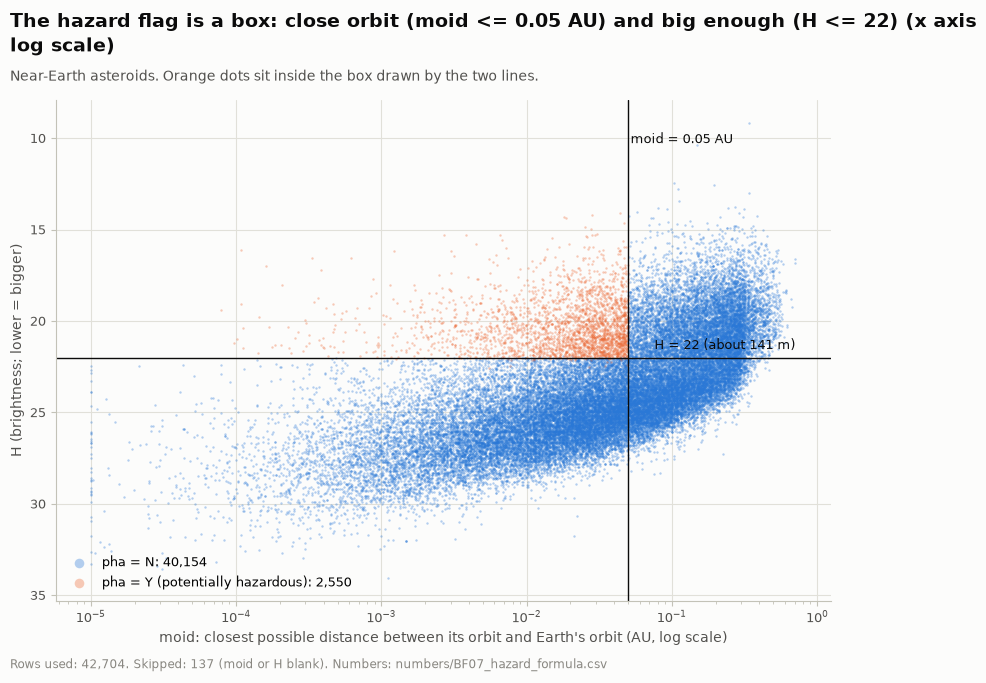

1 numbers/BF01_asteroid_belt_lanes.csv
2 numbers/BF02_darker_farther_out.csv
3 numbers/BF03_spin_limit.csv
4 numbers/BF04_discovery_chart_2025.csv
5 numbers/BF05_neptune_rhythm.csv
6 numbers/BF06_trojan_swarms.csv
7 numbers/BF07_hazard_formula.csv


In [8]:
F = Facts(7, "hazard_formula")
astr = ast[is_ast]
rule = (astr["moid"] <= 0.05) & (astr["H"] <= 22)
pha_y = astr["pha"] == "Y"
F.add("ast_rows", len(astr)); F.add("pha_filled", int(astr["pha"].notna().sum()))
F.rule("moid_cut", 0.05, "0.05", "AU"); F.rule("H_cut", 22, "22")
F.add("pha_y", int(pha_y.sum())); F.add("match", int((pha_y & rule).sum()))
F.add("match_pct", 100 * (pha_y & rule).sum() / pha_y.sum(), p(100 * (pha_y & rule).sum() / pha_y.sum(), 1))
exc = astr[pha_y & ~rule]
F.add("exceptions", len(exc)); F.add("exc_H_min", exc["H"].min(), d(exc["H"].min(), 2)); F.add("exc_H_max", exc["H"].max(), d(exc["H"].max(), 2))
F.add("pha_n_rule_yes", int(((astr["pha"] == "N") & rule).sum()))
F.add("moid_km", 0.05 * hp.AU_KM / 1e6, d(0.05 * hp.AU_KM / 1e6, 1), "million km")
F.add("moid_ld", 0.05 / hp.LD_AU, d(0.05 / hp.LD_AU, 1), "lunar distances")
F.add("size_H22", hp.size_from_H(22, 0.14) * 1000, n0(hp.size_from_H(22, 0.14) * 1000), "m")
neo_y = astr["neo"] == "Y"
F.add("neo_y", int(neo_y.sum())); F.add("neo_rule", int((neo_y & (astr["q"] < 1.3)).sum())); F.rule("q_cut", 1.3, "1.3", "AU")
F.add("neo_n_at_1_3", int(((astr["neo"] == "N") & (astr["q"] <= 1.3)).sum()))
yr4 = desig("(2024 YR4)")
F.add("yr4_H", yr4["H"], d(yr4["H"], 1)); F.add("yr4_moid", yr4["moid"], g(yr4["moid"], 2), "AU")
F.add("yr4_size", hp.size_from_H(yr4["H"], 0.14) * 1000, n0(hp.size_from_H(yr4["H"], 0.14) * 1000), "m")
F.add("yr4_pha", 0, str(yr4["pha"]), source="our data (flag)")
F.outside("yr4_chance", 3, "3%", source="Field Guide (news in early 2025)")
F.add("yr4_name", 0, yr4["full_name"].strip("()"), source="our data (name)")
F.add("yr4_q", yr4["q"], d(yr4["q"], 2), "AU")
print(F.table().to_string()); f7 = F.save()

# chart: near-Earth asteroids, moid against H, with the hazard box
ne = astr[neo_y & astr["moid"].notna() & astr["H"].notna()]
fig, ax = plt.subplots(figsize=(10, 6.5))
for flag, col, lab in [("N", hp.SERIES[0], "pha = N"), ("Y", hp.SERIES[1], "pha = Y (potentially hazardous)")]:
    q_ = ne[ne["pha"] == flag]
    ax.scatter(q_["moid"].clip(lower=1e-5), q_["H"], s=3, alpha=0.35, color=col, linewidths=0, rasterized=True,
               label=f"{lab}: {len(q_):,}")
ax.axvline(0.05, color=hp.INK, lw=1); ax.axhline(22, color=hp.INK, lw=1)
ax.text(0.052, ne["H"].min() + 0.5, "moid = 0.05 AU", fontsize=9, color=hp.INK, va="top")
ax.text(ne["moid"].max(), 21.7, "H = 22 (about 141 m)", fontsize=9, color=hp.INK, ha="right", va="bottom")
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("moid: closest possible distance between its orbit and Earth's orbit (AU, log scale)")
ax.set_ylabel("H (brightness; lower = bigger)")
ax.legend(loc="lower left", markerscale=4)
hp.add_titles(fig, "The hazard flag is a box: close orbit (moid <= 0.05 AU) and big enough (H <= 22) (x axis log scale)",
              "Near-Earth asteroids. Orange dots sit inside the box drawn by the two lines.",
              hp.caption(len(ne), int(neo_y.sum()) - len(ne), "moid or H blank", "numbers/BF07_hazard_formula.csv"))
c7 = hp.save_chart(fig, "BF07_hazard_box"); plt.show()
hp.log_entry("A-BF07", "Beginner finding 7 chart: moid against H for near-Earth asteroids", step=6, chart=c7, numbers=f7,
             rows_used=len(ne), rows_skipped=f"{int(neo_y.sum()) - len(ne):,} (moid or H blank)",
             key_numbers=[f"pha = Y: {int(pha_y.sum()):,}; inside the box: {int((pha_y & rule).sum()):,}"],
             what_it_shows="Almost every potentially hazardous asteroid sits inside the box moid <= 0.05 AU and H <= 22.")
for nn, f_ in enumerate([f1, f2, f3, f4, f5, f6, f7], 1):
    print(nn, f_)

## Plain version: "Meet the data" numbers and one plain chart per finding

The numbers in part A's "Meet the data" text are saved to `numbers/BM_A_meet_asteroids.csv`. Each finding gets a new,
simpler chart (`charts/K01_...png` to `charts/K07_...png`, plotted numbers in `numbers/K0n_...csv`) drawn with
`simple_charts`: big text, plain axis numbers, arrows pointing at the answer. The old charts are kept.

In [9]:
kc.plain_style()
M = Meet("A", "meet_asteroids")
M.add("rows_total", N_ALL); M.add("n_columns", len(hp.columns("asteroids")))
M.add("read_days", N_ALL / 86400, n0(N_ALL / 86400), "days", source="our data (rows ÷ seconds in a day)")
kinds = ast["kind"].value_counts()
M.add("asteroids", int(is_ast.sum())); M.add("numbered", int(kinds.get("an", 0))); M.add("unnumbered", int(kinds.get("au", 0)))
M.add("comets", int(ast["kind"].isin(["cn", "cu"]).sum()))
M.add("asteroid_pct", 100 * is_ast.mean(), p(100 * is_ast.mean(), 1))
M.add("neo_y", int((ast["neo"] == "Y").sum())); M.add("pha_y", int((ast["pha"] == "Y").sum()))
M.add("mba", int((ast["class"] == "MBA").sum()))
M.add("mba_pct", 100 * (ast["class"] == "MBA").mean(), p(100 * (ast["class"] == "MBA").mean()))
for col_, key_ in [("diameter", "diam"), ("albedo", "albedo"), ("rot_per", "rot")]:
    share_ = 100 * ast.loc[is_ast, col_].notna().mean()
    M.add(f"{key_}_share", share_, p(share_, 0) if share_ >= 1 else p(share_, 1))
partial = ast.loc[ast["first_obs"].str.contains(r"\?", regex=True, na=False), "first_obs"]
M.add("partial_dates", len(partial)); M.add("partial_example", 0, partial.iloc[0], source="our data (a date with question marks)")
num_ = int(ceres["full_name"].strip().split()[0])
M.add("ceres_number", num_, str(num_))
M.add("ceres_name", 0, ceres["name"], source="our data (name)"); M.add("ceres_kind", 0, ceres["kind"], source="our data (code)")
M.add("ceres_class", 0, ceres["class"], source="our data (code)")
M.add("ceres_neo", 0, ceres["neo"], source="our data (flag)"); M.add("ceres_pha", 0, ceres["pha"], source="our data (flag)")
for col_, key_, k_ in [("a", "a", 3), ("q", "q", 2), ("e", "e", 2), ("i", "i", 1), ("per_y", "per", 2), ("om", "om", 1), ("w", "w", 1),
                       ("ma", "ma", 1), ("H", "H", 2), ("diameter", "d", 1), ("albedo", "albedo", 2), ("rot_per", "rot", 2), ("moid", "moid", 2)]:
    M.add(f"ceres_{key_}", ceres[col_], d(ceres[col_], k_))
M.add("ceres_first_obs", 0, ceres["first_obs"], source="our data (date)")
M.add("ceres_day_vs_earth", 24 / ceres["rot_per"], d(24 / ceres["rot_per"], 1), source="our data (24 hours ÷ Ceres's spin time)")
M.rule("hours_per_day", 24, "24", "hours")
apophis = named("Apophis")
M.add("apophis_neo", 0, apophis["neo"], source="our data (flag)"); M.add("apophis_pha", 0, apophis["pha"], source="our data (flag)")
M.add("apophis_moid", apophis["moid"], g(apophis["moid"], 2), "AU"); M.add("apophis_moid_km", apophis["moid"] * hp.AU_KM, n0(apophis["moid"] * hp.AU_KM), "km")
M.add("apophis_H", apophis["H"], d(apophis["H"], 2))
# the picture of a path (K00A): a made-up asteroid, and three stretch numbers
Q_DEMO, q_DEMO = 3.3, 1.3
M.rule("demo_q", q_DEMO, d(q_DEMO, 1), "AU"); M.rule("demo_Q", Q_DEMO, d(Q_DEMO, 1), "AU")
M.add("demo_a", (q_DEMO + Q_DEMO) / 2, d((q_DEMO + Q_DEMO) / 2, 1), "AU", source="rule we used: (closest + farthest) ÷ 2")
M.rule("demo_two", 2, "2")
M.add("demo_moid", q_DEMO - 1, d(q_DEMO - 1, 1), "AU", source="rule we used: closest point minus Earth's distance (1)")
E_DEMO = [0, 0.5, 0.9]
for k_, e_ in enumerate(E_DEMO, 1):
    M.rule(f"e_demo{k_}", e_, d(e_, 1) if e_ else "0")
print(M.table().to_string()); fm = M.save()

                   key         value       shown   unit                                                  source
0           rows_total  1.582869e+06   1,582,869                                                       our data
1            n_columns  2.900000e+01          29                                                       our data
2            read_days  1.832024e+01          18   days                      our data (rows ÷ seconds in a day)
3            asteroids  1.578786e+06   1,578,786                                                       our data
4             numbered  8.959100e+05     895,910                                                       our data
5           unnumbered  6.828760e+05     682,876                                                       our data
6               comets  4.083000e+03       4,083                                                       our data
7         asteroid_pct  9.974205e+01       99.7%                                                       o

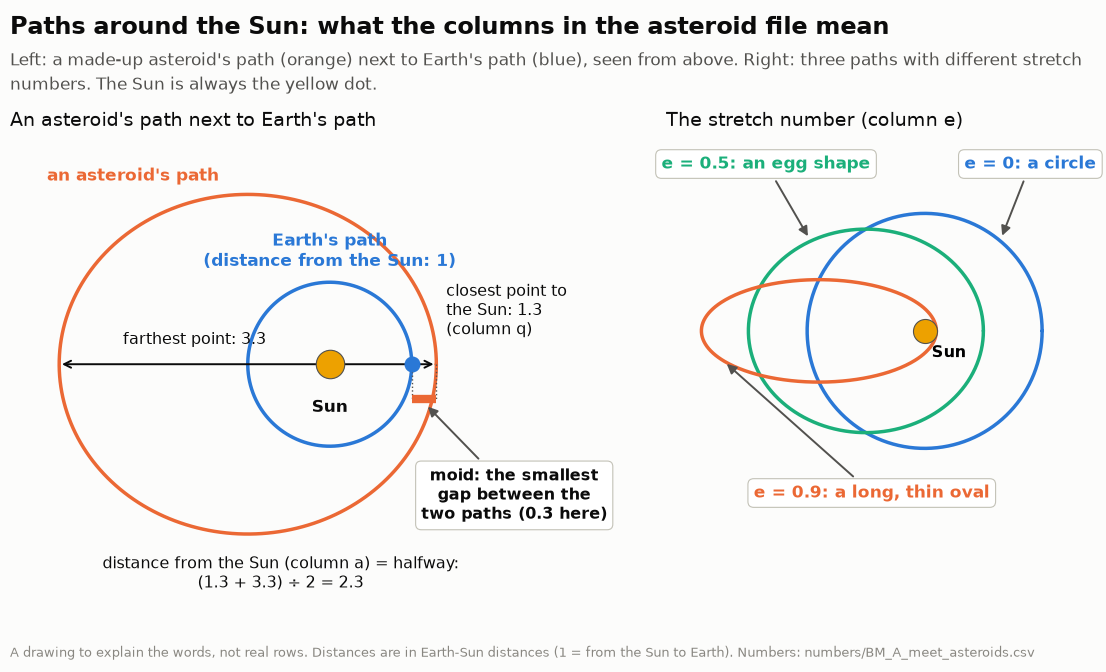

In [10]:
# K00A: a picture of the words used for paths around the Sun (a made-up asteroid, not a real row)
from matplotlib.patches import Ellipse  # noqa: E402

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 6.6), gridspec_kw={"width_ratios": [1.3, 1]})
a_ = (q_DEMO + Q_DEMO) / 2; e_ = (Q_DEMO - q_DEMO) / (Q_DEMO + q_DEMO); b_ = a_ * np.sqrt(1 - e_ ** 2); c_ = a_ * e_
t_ = np.linspace(0, 2 * np.pi, 400)
axL.plot(np.cos(t_), np.sin(t_), color=kc.MAIN, lw=2.5)
axL.plot(a_ * np.cos(t_) - c_, b_ * np.sin(t_), color=kc.HIGHLIGHT, lw=2.5)
axL.scatter([0], [0], s=420, color=hp.SERIES[3], zorder=5, edgecolor=hp.INK_2, linewidth=0.8)
axL.text(0, -0.42, "Sun", ha="center", va="top", fontsize=12.5, fontweight="bold", color=hp.INK)
axL.scatter([1], [0], s=110, color=kc.MAIN, zorder=6)
kc.label(axL, 0.0, 1.13, "Earth's path\n(distance from the Sun: 1)", ha="center", va="bottom", color=kc.MAIN, bold=True)
kc.label(axL, -a_ - c_ + 0.9, b_ + 0.12, "an asteroid's path", ha="center", va="bottom", color=hp.SERIES[1], bold=True)
# closest point q and farthest point
axL.annotate("", xy=(q_DEMO, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="<->", color=hp.INK, lw=1.4))
kc.label(axL, q_DEMO + 0.12, 0.3, f"closest point to\nthe Sun: {d(q_DEMO, 1)}\n(column q)", ha="left", va="bottom", fontsize=11.5)
axL.annotate("", xy=(-Q_DEMO, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="<->", color=hp.INK, lw=1.4))
kc.label(axL, -Q_DEMO / 2, 0.2, f"farthest point: {d(Q_DEMO, 1)}", ha="center", va="bottom", fontsize=11.5)
kc.label(axL, -0.6, -b_ - 0.25, f"distance from the Sun (column a) = halfway:\n({d(q_DEMO, 1)} + {d(Q_DEMO, 1)}) ÷ 2 = {d(a_, 1)}",
         ha="center", va="top", fontsize=11.5)
# moid: the smallest gap between the two paths
for x_ in (1.0, q_DEMO):
    axL.plot([x_, x_], [0, -0.42], color=hp.INK_2, lw=1, ls=":")
axL.plot([1.0, q_DEMO], [-0.42, -0.42], color=hp.SERIES[1], lw=6, solid_capstyle="butt")
kc.point_at(axL, ((1.0 + q_DEMO) / 2, -0.47), f"moid: the smallest\ngap between the\ntwo paths ({d(q_DEMO - 1, 1)} here)",
            (2.25, -1.6), fontsize=11.5)
axL.set_aspect("equal"); axL.set_xlim(-Q_DEMO - 0.6, q_DEMO + 1.6); axL.set_ylim(-b_ - 1.2, b_ + 0.7); axL.axis("off")
axL.set_title("An asteroid's path next to Earth's path", fontsize=14, color=hp.INK, loc="left", pad=8)
cols_ = [kc.MAIN, hp.SERIES[2], kc.HIGHLIGHT]
for e_d, col_ in zip(E_DEMO, cols_):
    bd = np.sqrt(1 - e_d ** 2)
    axR.plot(np.cos(t_) - e_d, bd * np.sin(t_), color=col_, lw=2.5)
axR.scatter([0], [0], s=300, color=hp.SERIES[3], zorder=5, edgecolor=hp.INK_2, linewidth=0.8)
axR.text(0.06, -0.12, "Sun", ha="left", va="top", fontsize=11.5, fontweight="bold")
def on_loop(e_d, deg):
    return np.cos(np.radians(deg)) - e_d, np.sqrt(1 - e_d ** 2) * np.sin(np.radians(deg))
kc.point_at(axR, on_loop(0, 50), "e = 0: a circle", (0.9, 1.42), color=cols_[0])
kc.point_at(axR, on_loop(0.5, 118), "e = 0.5: an egg shape", (-1.35, 1.42), color=cols_[1])
kc.point_at(axR, on_loop(0.9, 215), "e = 0.9: a long, thin oval", (-0.45, -1.38), color=cols_[2])
axR.set_aspect("equal"); axR.set_xlim(-2.2, 1.45); axR.set_ylim(-1.6, 1.65); axR.axis("off")
axL.set_anchor("N"); axR.set_anchor("N")
axR.set_title("The stretch number (column e)", fontsize=14, color=hp.INK, loc="left", pad=8)
kc.titles(fig, "Paths around the Sun: what the columns in the asteroid file mean",
          "Left: a made-up asteroid's path (orange) next to Earth's path (blue), seen from above. "
          "Right: three paths with different stretch numbers. The Sun is always the yellow dot.",
          "A drawing to explain the words, not real rows. Distances are in Earth-Sun distances (1 = from the Sun to Earth). "
          "Numbers: numbers/BM_A_meet_asteroids.csv")
k00 = kc.save(fig, "K00A_paths_around_the_sun"); plt.show()
hp.log_entry("A-K00A", "Simple picture: the words used for paths around the Sun", step=6, chart=k00, numbers=fm,
             what_it_shows="A made-up path shows the closest point (q), farthest point, distance from the Sun (a), moid and stretch number (e).")

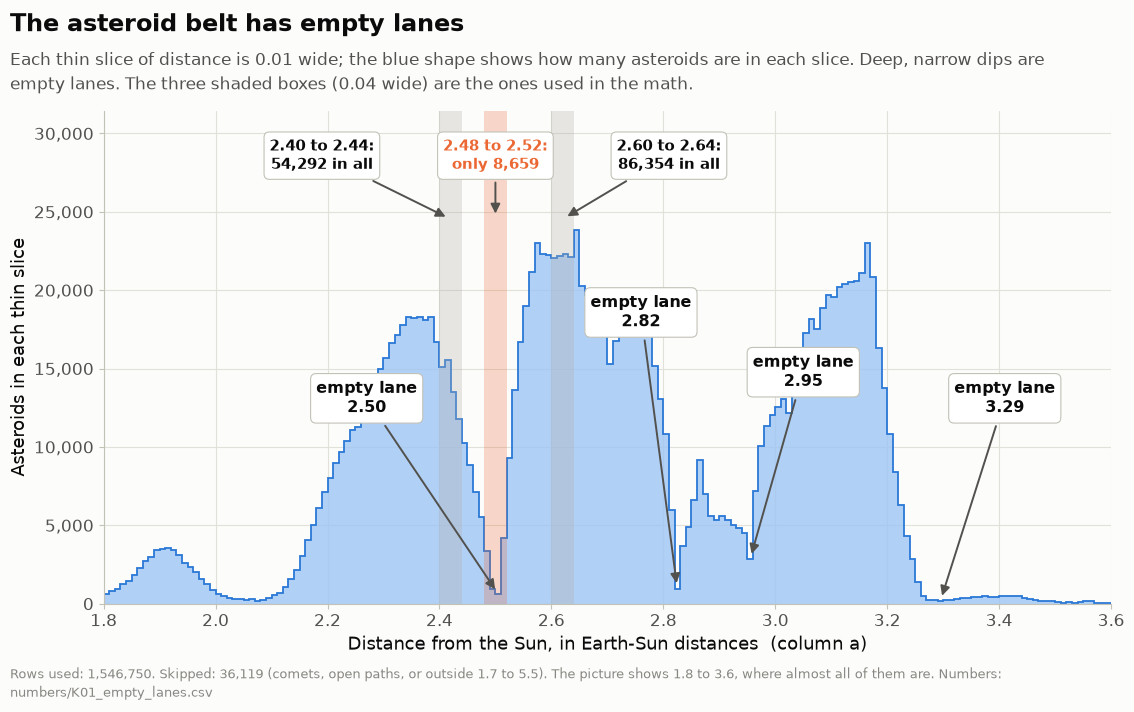

In [11]:
# K01: the empty lanes, a plain (not log) count of asteroids in each slice 0.01 wide, 1.8 to 3.6
ZOOM = (1.8, 3.6)
k1 = np.floor(np.round(a1 * 1000) / 10).astype(int)          # slice index: 248 = from 2.48 up to (not including) 2.49
cnt1 = k1.value_counts().sort_index().reindex(range(int(ZOOM[0] * 100), int(ZOOM[1] * 100)), fill_value=0)
t1 = pd.DataFrame({"slice_from": cnt1.index / 100, "slice_to": (cnt1.index + 1) / 100, "asteroids": cnt1.values})
n1 = hp.save_numbers(t1, "K01_empty_lanes")
fig, ax = plt.subplots(figsize=(13, 6.4))
edges1 = np.r_[t1["slice_from"].values, t1["slice_to"].values[-1]]
ax.stairs(t1["asteroids"], edges1, fill=True, color=hp.SEQ_BLUE[2], alpha=0.8)
ax.stairs(t1["asteroids"], edges1, color=kc.MAIN, lw=1.3)
top1 = t1["asteroids"].max()
for k_, (lo, hi, txt, lx) in enumerate([(2.40, 2.44, f"{d(2.40, 2)} to {d(2.44, 2)}:\n{n0(inside)} in all", 2.19),
                                         (2.48, 2.52, f"{d(2.48, 2)} to {d(2.52, 2)}:\nonly {n0(gap)}", 2.50),
                                         (2.60, 2.64, f"{d(2.60, 2)} to {d(2.64, 2)}:\n{n0(outside)} in all", 2.81)]):
    ax.axvspan(lo, hi, color=kc.HIGHLIGHT if k_ == 1 else hp.GRAY, alpha=0.25 if k_ == 1 else 0.3, lw=0)
    kc.point_at(ax, ((lo + hi) / 2, top1 * 1.03), txt, (lx, top1 * 1.2), fontsize=11,
                color=hp.SERIES[1] if k_ == 1 else hp.INK)
lane_lbl = [(r["lowest_bin_AU"], f"empty lane\n{d(r['lowest_bin_AU'], 2)}") for _, r in main_dips.iterrows()]
offsets = {0: (-0.0, 0.62), 1: (-0.06, 0.78), 2: (0.1, 0.62), 3: (0.12, 0.55)}
for k_, (x_, txt) in enumerate(lane_lbl):
    y_ = int(t1.loc[np.isclose(t1["slice_from"], x_), "asteroids"].iloc[0])
    dx, fy = offsets.get(k_, (0.1, 0.6))
    if k_ == 0:
        continue                                # the 2.50 lane is named by the shaded box above it
    kc.point_at(ax, (x_ + 0.005, y_), txt, (x_ + dx, top1 * fy), fontsize=11.5)
kc.point_at(ax, (2.505, int(t1.loc[np.isclose(t1["slice_from"], 2.50), "asteroids"].iloc[0])), "empty lane\n2.50",
            (2.27, top1 * 0.55), fontsize=11.5)
ax.set_xlim(*ZOOM); ax.set_ylim(0, top1 * 1.32)
ax.set_xlabel("Distance from the Sun, in Earth-Sun distances  (column a)")
ax.set_ylabel("Asteroids in each thin slice")
kc.plain_axis(ax, "y")
kc.titles(fig, "The asteroid belt has empty lanes",
          f"Each thin slice of distance is {d(0.01, 2)} wide; the blue shape shows how many asteroids are in each slice. "
          f"Deep, narrow dips are empty lanes. The three shaded boxes ({d(0.04, 2)} wide) are the ones used in the math.",
          hp.caption(int(rows1.sum()), N_ALL - int(rows1.sum()), "comets, open paths, or outside 1.7 to 5.5",
                     n1, extra=f"The picture shows {d(ZOOM[0], 1)} to {d(ZOOM[1], 1)}, where almost all of them are."))
c1_ = kc.save(fig, "K01_empty_lanes"); plt.show()
hp.log_entry("A-K01", "Simple chart for finding 1: empty lanes in the asteroid belt", step=6, chart=c1_, numbers=n1,
             rows_used=int(rows1.sum()), key_numbers=[f"2.48 to 2.52: {n0(gap)}; 2.40 to 2.44: {n0(inside)}; 2.60 to 2.64: {n0(outside)}"],
             what_it_shows="Plain counts per 0.01 slice: the lanes at 2.50, 2.82, 2.95 and 3.29 are deep dips.")

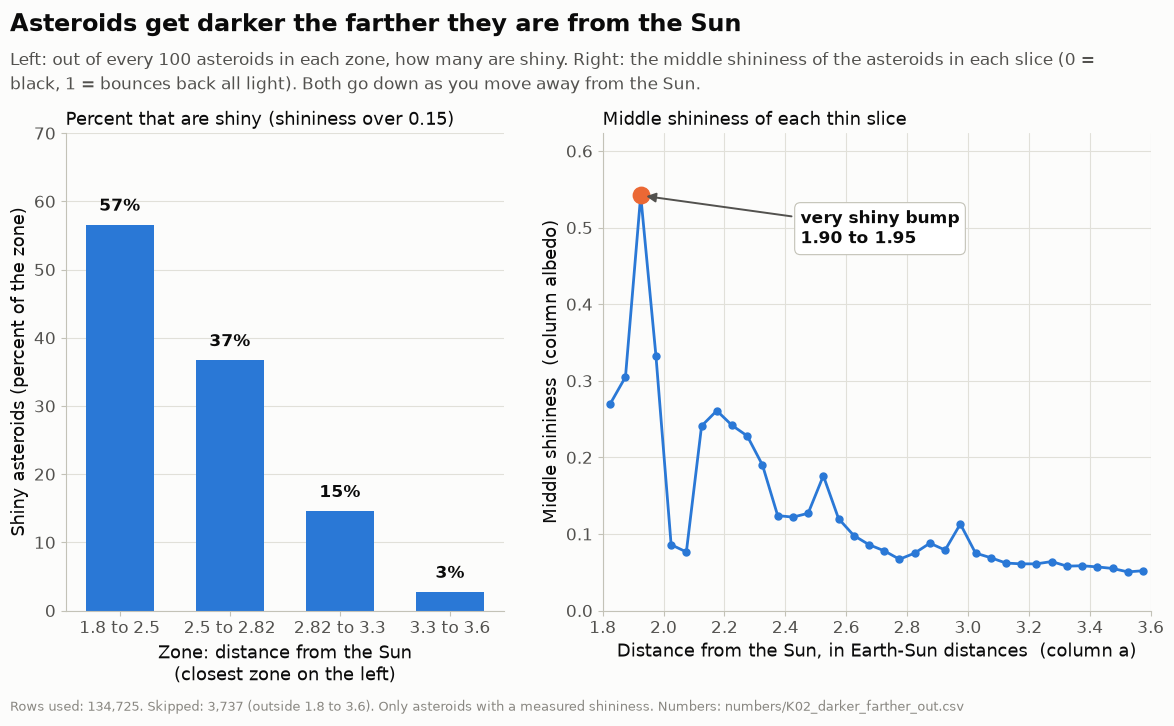

In [12]:
# K02: shiny asteroids get rarer farther out (left), and the middle shininess per slice (right)
rows2 = []
for lo, hi in ZONES:
    z = alb & (ast["a"] >= lo) & (ast["a"] < hi)
    rows2.append({"zone_from": lo, "zone_to": hi, "asteroids": int(z.sum()), "shiny": int((ast.loc[z, "albedo"] > 0.15).sum())})
t2 = pd.DataFrame(rows2); t2["shiny_pct"] = 100 * t2["shiny"] / t2["asteroids"]
sl2 = t10[(t10["a_from"] >= 1.8 - 1e-9) & (t10["a_to"] <= 3.6 + 1e-9)].copy()
n2 = hp.save_numbers(t2, "K02_darker_farther_out"); hp.save_numbers(sl2, "K02_darker_farther_out_slices")
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1, 1.25]})
xl = [f"{lo:g} to {hi:g}" for lo, hi in ZONES]
axL.bar(range(4), t2["shiny_pct"], color=kc.MAIN, width=0.62)
for k_, v in enumerate(t2["shiny_pct"]):
    kc.label(axL, k_, v + 1.5, p(v), ha="center", va="bottom", bold=True)
axL.set_xticks(range(4), xl); axL.set_ylim(0, 70); axL.grid(axis="x", visible=False)
axL.set_xlabel("Zone: distance from the Sun\n(closest zone on the left)")
axL.set_ylabel("Shiny asteroids (percent of the zone)")
axL.set_title("Percent that are shiny (shininess over 0.15)", fontsize=13, color=hp.INK, loc="left")
mid2 = (sl2["a_from"] + sl2["a_to"]) / 2
axR.plot(mid2, sl2["median_albedo"], color=kc.MAIN, lw=2, marker="o", ms=5)
sp = sl2.loc[sl2["median_albedo"].idxmax()]
axR.scatter([(sp["a_from"] + sp["a_to"]) / 2], [sp["median_albedo"]], s=140, color=kc.HIGHLIGHT, zorder=6)
kc.point_at(axR, ((sp["a_from"] + sp["a_to"]) / 2, sp["median_albedo"]),
            f"very shiny bump\n{d(sp['a_from'], 2)} to {d(sp['a_to'], 2)}", (2.45, sp["median_albedo"] * 0.92), ha="left")
axR.set_xlabel("Distance from the Sun, in Earth-Sun distances  (column a)")
axR.set_ylabel("Middle shininess  (column albedo)")
axR.set_ylim(0, sp["median_albedo"] * 1.15); axR.set_xlim(1.8, 3.6)
axR.set_title("Middle shininess of each thin slice", fontsize=13, color=hp.INK, loc="left")
kc.titles(fig, "Asteroids get darker the farther they are from the Sun",
          "Left: out of every 100 asteroids in each zone, how many are shiny. Right: the middle shininess of the asteroids in each "
          "slice (0 = black, 1 = bounces back all light). Both go down as you move away from the Sun.",
          hp.caption(int(t2["asteroids"].sum()), int(alb.sum()) - int(t2["asteroids"].sum()), "outside 1.8 to 3.6",
                     n2, extra="Only asteroids with a measured shininess."))
c2_ = kc.save(fig, "K02_darker_farther_out"); plt.show()
hp.log_entry("A-K02", "Simple chart for finding 2: shiny share by zone and middle shininess by slice", step=6, chart=c2_, numbers=n2,
             rows_used=int(t2["asteroids"].sum()), key_numbers=[" -> ".join(p(v) for v in t2["shiny_pct"])],
             what_it_shows="The share of shiny asteroids falls zone by zone; a very shiny bump sits at 1.90 to 1.95.")

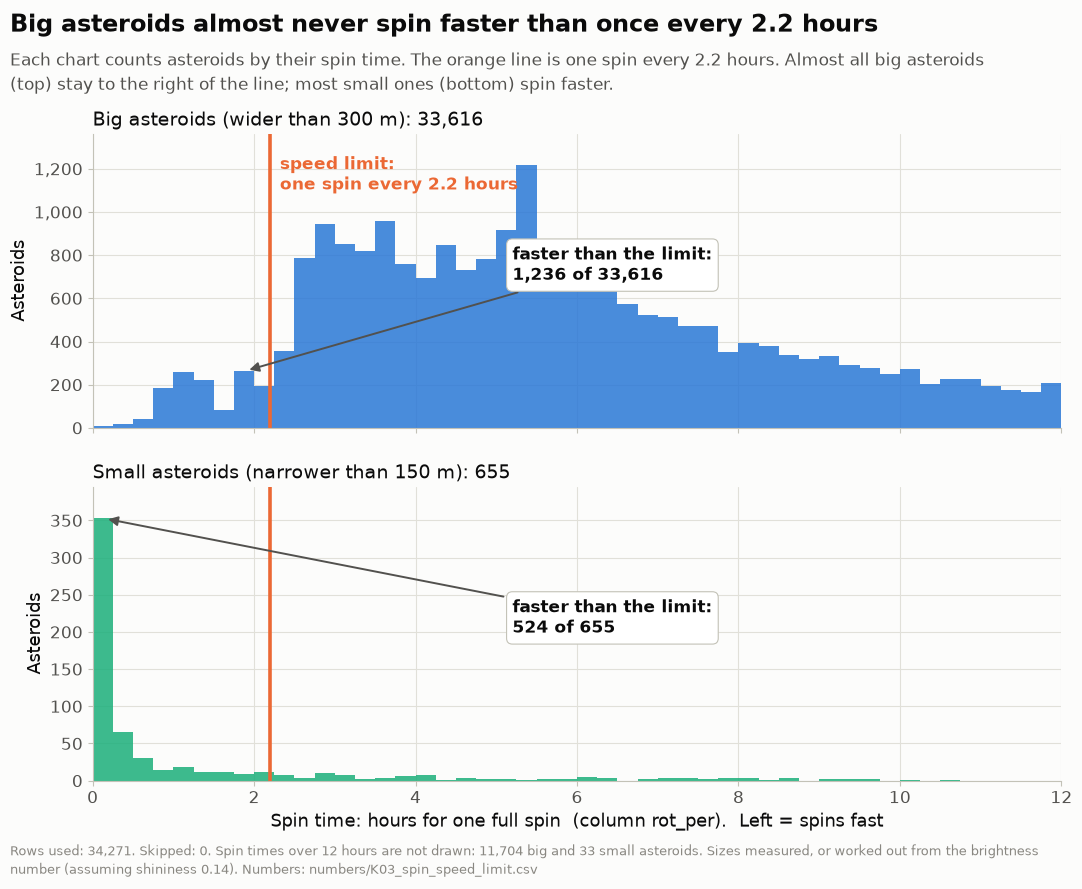

In [13]:
# K03: spin times of big and small asteroids, with the 2.2-hour speed limit
bins3 = np.arange(0, 12.0001, 0.25)
big_s, small_s = s3.loc[big, "rot_per"], s3.loc[small, "rot_per"]
cb, _ = np.histogram(big_s, bins3); cs, _ = np.histogram(small_s, bins3)
t3 = pd.DataFrame({"spin_from_h": bins3[:-1], "spin_to_h": bins3[1:], "big_asteroids": cb, "small_asteroids": cs})
n3 = hp.save_numbers(t3, "K03_spin_speed_limit")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12.5, 8.4), sharex=True)
for ax_, c_, col_, ttl, nfast, ntot in [(ax1, cb, kc.MAIN, f"Big asteroids (wider than 300 m): {n0(big.sum())}", int((big & fast).sum()), int(big.sum())),
                                         (ax2, cs, hp.SERIES[2], f"Small asteroids (narrower than 150 m): {n0(small.sum())}", int((small & fast).sum()), int(small.sum()))]:
    ax_.stairs(c_, bins3, fill=True, color=col_, alpha=0.85)
    ax_.axvline(2.2, color=kc.HIGHLIGHT, lw=2.6)
    ax_.set_title(ttl, fontsize=13.5, color=hp.INK, loc="left")
    ax_.set_ylabel("Asteroids")
    kc.plain_axis(ax_, "y")
    top_ = c_.max()
    i_ = int(np.argmax(c_[:8]))
    kc.point_at(ax_, (bins3[i_] + 0.125, c_[i_]), f"faster than the limit:\n{n0(nfast)} of {n0(ntot)}",
                (5.2, top_ * 0.62), ha="left")
    ax_.set_ylim(0, top_ * 1.12)
kc.label(ax1, 2.32, ax1.get_ylim()[1] * 0.93, "speed limit:\none spin every 2.2 hours", color=hp.SERIES[1], bold=True, va="top")
ax2.set_xlabel("Spin time: hours for one full spin  (column rot_per).  Left = spins fast")
ax2.set_xlim(0, 12)
kc.titles(fig, "Big asteroids almost never spin faster than once every 2.2 hours",
          "Each chart counts asteroids by their spin time. The orange line is one spin every 2.2 hours. "
          "Almost all big asteroids (top) stay to the right of the line; most small ones (bottom) spin faster.",
          hp.caption(int((big | small).sum()), 0, "", n3,
                     extra=f"Spin times over 12 hours are not drawn: {n0((big_s > 12).sum())} big and {n0((small_s > 12).sum())} small asteroids. "
                           f"Sizes measured, or worked out from the brightness number (assuming shininess 0.14)."))
c3_ = kc.save(fig, "K03_spin_speed_limit"); plt.show()
hp.log_entry("A-K03", "Simple chart for finding 3: spin times of big and small asteroids", step=6, chart=c3_, numbers=n3,
             rows_used=int((big | small).sum()), key_numbers=[f"big: {int((big & fast).sum()):,} of {int(big.sum()):,} faster than 2.2 h; small: {int((small & fast).sum()):,} of {int(small.sum()):,}"],
             what_it_shows="Big asteroids pile up just right of the 2.2-hour line and almost never cross it; small ones do.")

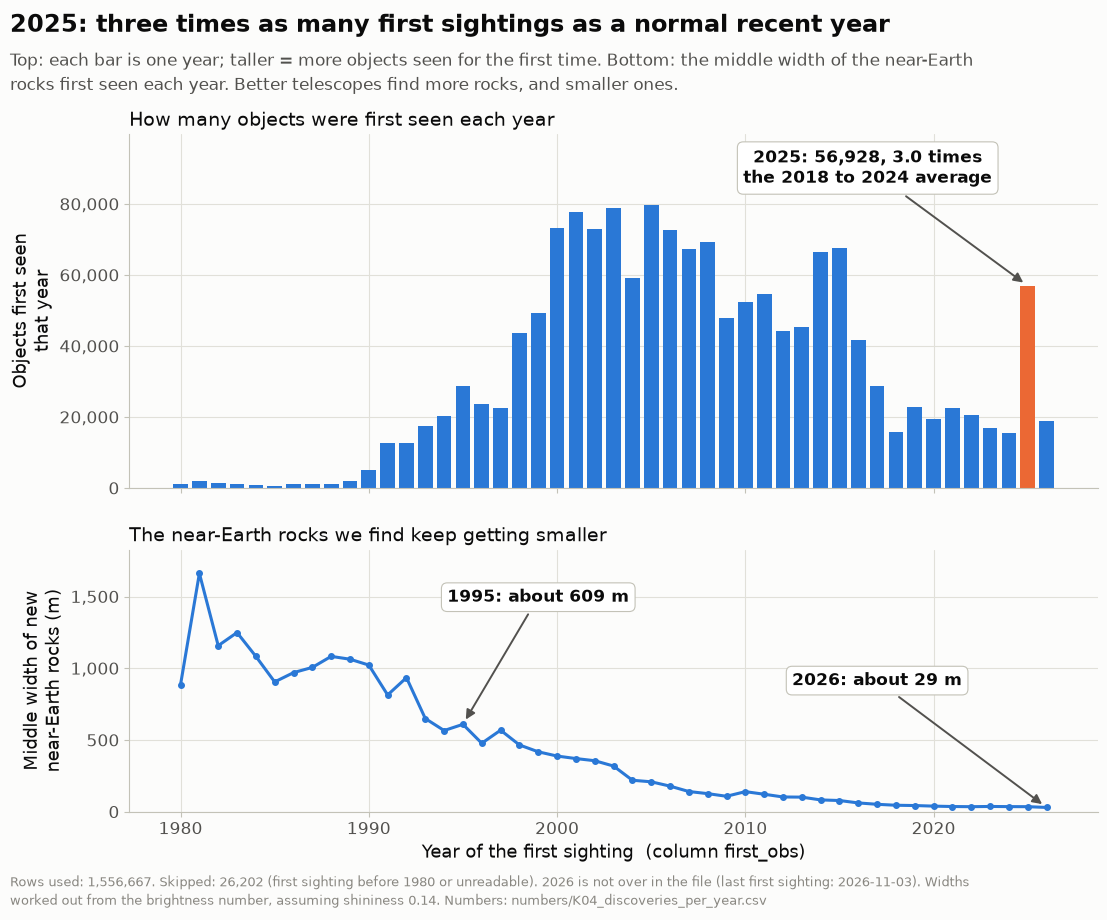

In [14]:
# K04: first sightings per year (top) and the middle width of new near-Earth asteroids (bottom)
yrs = np.arange(1980, 2027)
last_2026 = ast.loc[ast["first_obs"].str.startswith("2026", na=False), "first_obs"].max()
t4 = pd.DataFrame({"year": yrs, "first_sightings": py.reindex(yrs, fill_value=0).values.astype(int),
                   "neo_middle_width_m": pd.Series(hp.size_from_H(medH.values, 0.14) * 1000, index=medH.index.astype(int)).reindex(yrs).round(1).values})
n4 = hp.save_numbers(t4, "K04_discoveries_per_year")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12.5, 8.8), sharex=True, gridspec_kw={"height_ratios": [1.35, 1]})
ax1.bar(yrs, t4["first_sightings"], color=[kc.HIGHLIGHT if y_ == 2025 else kc.MAIN for y_ in yrs], width=0.78)
kc.point_at(ax1, (2025, py[2025]), f"2025: {n0(py[2025])}, {d(py[2025] / r18.mean(), 1)} times\nthe 2018 to 2024 average",
            (2016.5, t4["first_sightings"].max() * 1.13), ha="center")
ax1.set_ylabel("Objects first seen\nthat year"); kc.plain_axis(ax1, "y"); ax1.set_ylim(0, t4["first_sightings"].max() * 1.25)
ax1.set_title("How many objects were first seen each year", fontsize=13.5, color=hp.INK, loc="left")
ax2.plot(yrs, t4["neo_middle_width_m"], color=kc.MAIN, lw=2.2, marker="o", ms=4)
for y_, off in [(1995, (1999, 0.9)), (2026, (2017, 0.55))]:
    v_ = float(t4.loc[t4["year"] == y_, "neo_middle_width_m"].iloc[0])
    kc.point_at(ax2, (y_, v_), f"{y_}: about {n0(v_)} m", (off[0], t4["neo_middle_width_m"].max() * off[1]))
ax2.set_ylabel("Middle width of new\nnear-Earth rocks (m)"); kc.plain_axis(ax2, "y"); ax2.set_ylim(0, t4["neo_middle_width_m"].max() * 1.1)
ax2.set_title("The near-Earth rocks we find keep getting smaller", fontsize=13.5, color=hp.INK, loc="left")
ax2.set_xlabel("Year of the first sighting  (column first_obs)")
kc.titles(fig, "2025: three times as many first sightings as a normal recent year",
          "Top: each bar is one year; taller = more objects seen for the first time. Bottom: the middle width of the "
          "near-Earth rocks first seen each year. Better telescopes find more rocks, and smaller ones.",
          hp.caption(int(yr.between(1980, 2026).sum()), N_ALL - int(yr.between(1980, 2026).sum()), "first sighting before 1980 or unreadable",
                     n4, extra=f"2026 is not over in the file (last first sighting: {last_2026}). Widths worked out from the brightness number, assuming shininess 0.14."))
c4_ = kc.save(fig, "K04_discoveries_per_year"); plt.show()
hp.log_entry("A-K04", "Simple chart for finding 4: first sightings per year and new near-Earth rock sizes", step=6, chart=c4_, numbers=n4,
             rows_used=int(yr.between(1980, 2026).sum()), key_numbers=[f"2025: {py[2025]:,}; 2018-2024 average {r18.mean():,.0f}"],
             what_it_shows="2025 is about three times a normal recent year; new near-Earth rocks shrank from hundreds of metres to tens.")

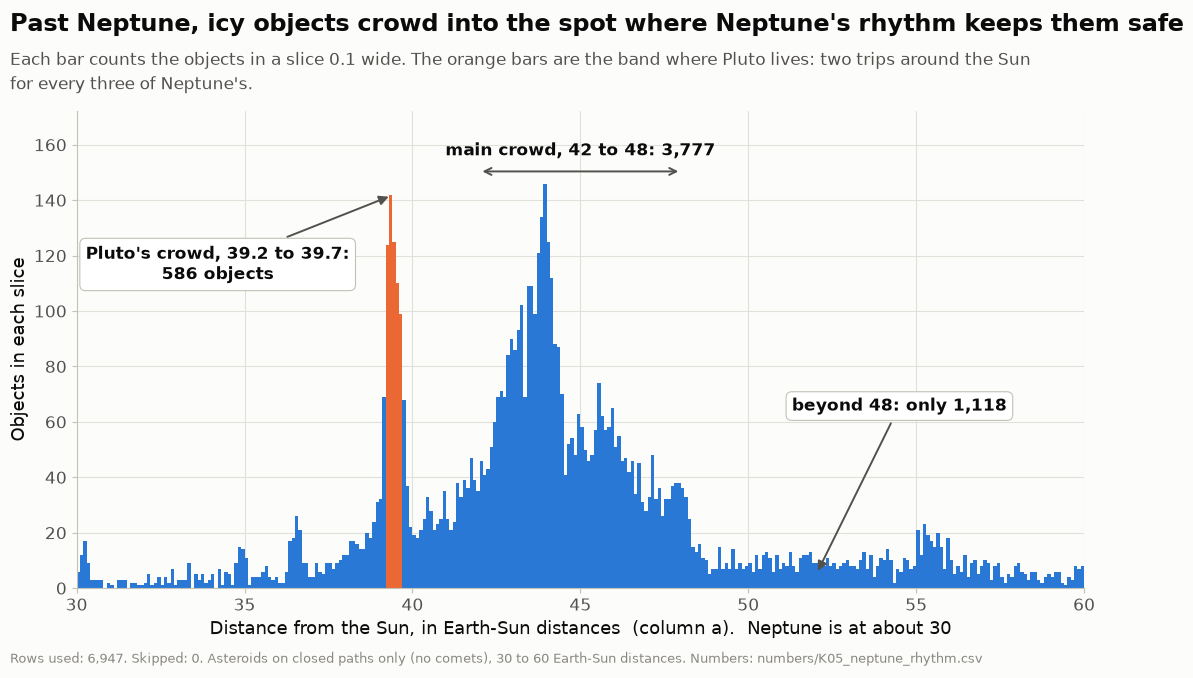

In [15]:
# K05: past Neptune, a plain count of objects in slices 0.1 wide, 30 to 60
k5 = np.floor(np.round(a5 * 1000) / 100).astype(int)          # slice index: 392 = from 39.2 up to (not including) 39.3
cnt5 = k5.value_counts().sort_index().reindex(range(300, 600), fill_value=0)
t5 = pd.DataFrame({"slice_from": cnt5.index / 10, "slice_to": (cnt5.index + 1) / 10, "objects": cnt5.values})
n5 = hp.save_numbers(t5, "K05_neptune_rhythm")
fig, ax = plt.subplots(figsize=(13, 6.2))
band_ = (t5["slice_from"] >= 39.2 - 1e-9) & (t5["slice_to"] <= 39.7 + 1e-9)
ax.bar(t5["slice_from"] + 0.05, t5["objects"], width=0.1, color=np.where(band_, kc.HIGHLIGHT, kc.MAIN), linewidth=0)
top5 = t5["objects"].max()
kc.point_at(ax, (39.45, t5.loc[band_, "objects"].max()), f"Pluto's crowd, 39.2 to 39.7:\n{n0(w5(39.2, 39.7))} objects",
            (34.2, top5 * 0.8), ha="center")
ax.annotate("", xy=(42, top5 * 1.03), xytext=(48, top5 * 1.03), arrowprops=dict(arrowstyle="<->", color=hp.INK_2, lw=1.4))
kc.label(ax, 45, top5 * 1.06, f"main crowd, 42 to 48: {n0(w5(42, 48))}", ha="center", va="bottom", bold=True)
kc.point_at(ax, (52, top5 * 0.03), f"beyond 48: only {n0(w5(48, 60))}", (54.5, top5 * 0.45), ha="center")
ax.set_xlim(30, 60); ax.set_ylim(0, top5 * 1.18)
ax.set_xlabel("Distance from the Sun, in Earth-Sun distances  (column a).  Neptune is at about 30")
ax.set_ylabel("Objects in each slice"); kc.plain_axis(ax, "y")
kc.titles(fig, "Past Neptune, icy objects crowd into the spot where Neptune's rhythm keeps them safe",
          "Each bar counts the objects in a slice 0.1 wide. The orange bars are the band where Pluto lives: "
          "two trips around the Sun for every three of Neptune's.",
          hp.caption(int(m5.sum()), 0, "", n5, extra="Asteroids on closed paths only (no comets), 30 to 60 Earth-Sun distances."))
c5_ = kc.save(fig, "K05_neptune_rhythm"); plt.show()
hp.log_entry("A-K05", "Simple chart for finding 5: objects past Neptune, slices 0.1 wide", step=6, chart=c5_, numbers=n5,
             rows_used=int(m5.sum()), key_numbers=[f"39.2 to 39.7: {w5(39.2, 39.7):,}; 42 to 48: {w5(42, 48):,}; beyond 48: {w5(48, 60):,}"],
             what_it_shows="A tall spike at Pluto's distance, a wide main crowd from 42 to 48, and almost nothing beyond 48.")

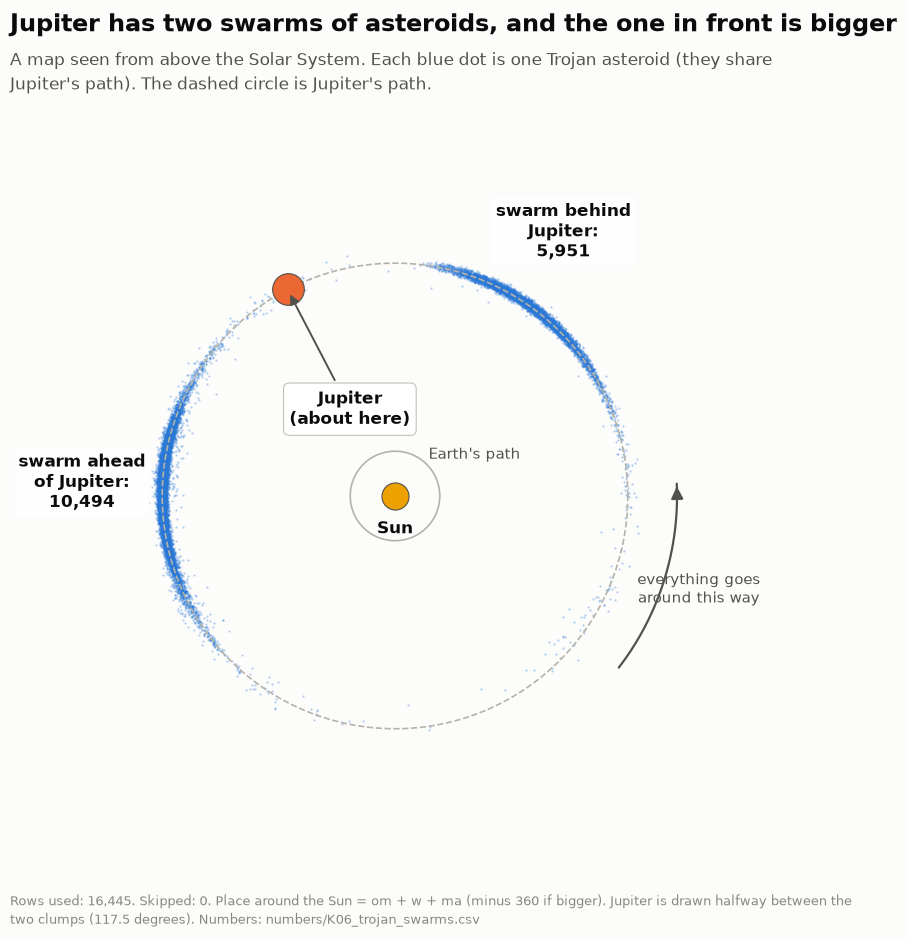

In [16]:
# K06: Jupiter's two swarms, seen from above the Solar System
aT = tj.loc[L.index, "a"]
th = np.radians(L)
J = (behind + short / 2) % 360
t6 = pd.DataFrame({"place_deg": L.round(2), "distance_from_sun": aT.round(3)})
n6 = hp.save_numbers(pd.DataFrame({"what": ["ahead of Jupiter", "behind Jupiter", "Jupiter (halfway between the clumps)"],
                                   "place_deg": [ahead, behind, J], "trojans": [n_ahead, n_behind, np.nan]}), "K06_trojan_swarms")
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(aT * np.cos(th), aT * np.sin(th), s=2.5, alpha=0.35, color=kc.MAIN, linewidths=0, rasterized=True)
tt = np.linspace(0, 2 * np.pi, 400)
JUP_A = 5.2
ax.plot(JUP_A * np.cos(tt), JUP_A * np.sin(tt), color=hp.GRAY, lw=1.2, ls="--")
ax.plot(np.cos(tt), np.sin(tt), color=hp.GRAY, lw=1.2)
ax.scatter([0], [0], s=380, color=hp.SERIES[3], zorder=6, edgecolor=hp.INK_2, linewidth=0.8)
kc.label(ax, 0, -0.55, "Sun", ha="center", va="top", bold=True)
kc.label(ax, 0.75, 0.75, "Earth's path", ha="left", va="bottom", fontsize=11, color=hp.INK_2)
jx, jy = JUP_A * np.cos(np.radians(J)), JUP_A * np.sin(np.radians(J))
ax.scatter([jx], [jy], s=520, color=kc.HIGHLIGHT, zorder=7, edgecolor=hp.INK_2, linewidth=0.8)
kc.point_at(ax, (jx, jy), "Jupiter\n(about here)", (jx * 0.42, jy * 0.42))
for ang, nn_, txt in [(ahead, n_ahead, "swarm ahead\nof Jupiter"), (behind, n_behind, "swarm behind\nJupiter")]:
    kc.label(ax, 7.0 * np.cos(np.radians(ang)), 7.0 * np.sin(np.radians(ang)), f"{txt}:\n{n0(nn_)}", ha="center", va="center",
             bold=True, box=True)
arc = np.radians(np.linspace(J + 205, J + 245, 50))
ax.plot(6.3 * np.cos(arc), 6.3 * np.sin(arc), color=hp.INK_2, lw=1.6)
ax.annotate("", xy=(6.3 * np.cos(arc[-1]), 6.3 * np.sin(arc[-1])), xytext=(6.3 * np.cos(arc[-3]), 6.3 * np.sin(arc[-3])),
            arrowprops=dict(arrowstyle="-|>", color=hp.INK_2, lw=1.6, mutation_scale=18))
kc.label(ax, 7.1 * np.cos(arc[25]), 7.1 * np.sin(arc[25]), "everything goes\naround this way", ha="center", va="center", fontsize=11, color=hp.INK_2)
ax.set_aspect("equal"); ax.set_xlim(-8.6, 8.6); ax.set_ylim(-8.6, 8.6); ax.axis("off")
kc.titles(fig, "Jupiter has two swarms of asteroids, and the one in front is bigger",
          "A map seen from above the Solar System. Each blue dot is one Trojan asteroid (they share Jupiter's path). "
          "The dashed circle is Jupiter's path.",
          hp.caption(len(L), 0, "", n6, extra=f"Place around the Sun = om + w + ma (minus 360 if bigger). Jupiter is drawn halfway between the two clumps ({d(J, 1)} degrees)."))
c6_ = kc.save(fig, "K06_trojan_swarms"); plt.show()
hp.log_entry("A-K06", "Simple chart for finding 6: Jupiter's Trojan swarms seen from above", step=6, chart=c6_, numbers=n6,
             rows_used=len(L), key_numbers=[f"ahead {n_ahead:,}, behind {n_behind:,}"],
             what_it_shows="Two clouds of Trojans, one ahead of and one behind Jupiter; the one ahead has more.")

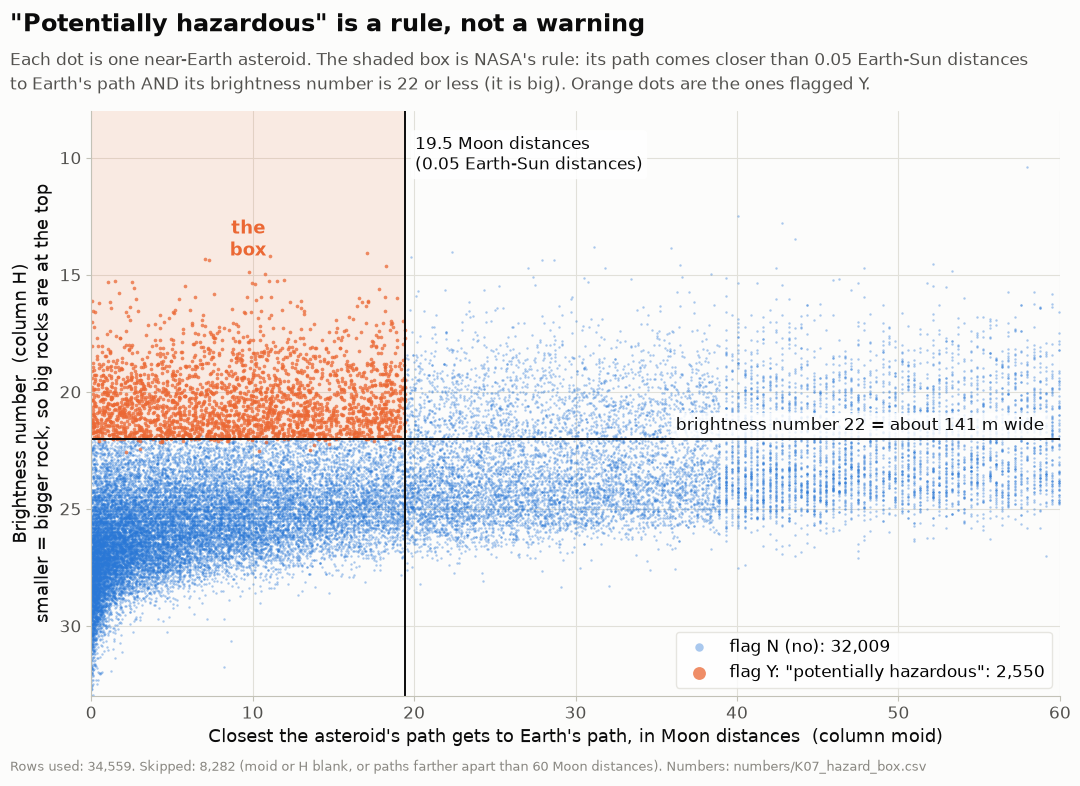

In [17]:
# K07: the hazard flag is a box: paths come close (moid) and the rock is big (brightness number H)
x7 = ne["moid"] / hp.LD_AU
show7 = x7 <= 60
t7 = pd.DataFrame({"moid_moon_distances": x7.round(3), "H": ne["H"], "pha": ne["pha"]})[show7]
n7 = hp.save_numbers(t7.groupby("pha").agg(asteroids=("H", "size")).reset_index(), "K07_hazard_box")
fig, ax = plt.subplots(figsize=(12.5, 7.6))
box_x = 0.05 / hp.LD_AU
ax.fill_between([0, box_x], 22, 8, color=kc.HIGHLIGHT, alpha=0.12, lw=0)
for flag, col_, lbl, sz in [("N", kc.MAIN, "flag N (no)", 3), ("Y", kc.HIGHLIGHT, "flag Y: \"potentially hazardous\"", 7)]:
    q_ = t7[t7["pha"] == flag]
    ax.scatter(q_["moid_moon_distances"], q_["H"], s=sz, alpha=0.4 if flag == "N" else 0.75, color=col_, linewidths=0,
               rasterized=True, label=f"{lbl}: {n0(len(q_))}")
ax.axvline(box_x, color=hp.INK, lw=1.4); ax.axhline(22, color=hp.INK, lw=1.4)
ax.set_xlim(0, 60); ax.set_ylim(33, 8)
kc.label(ax, box_x + 0.6, 9.0, f"{d(box_x, 1)} Moon distances\n(0.05 Earth-Sun distances)", ha="left", va="top", box=True)
kc.label(ax, 59, 21.8, f"brightness number 22 = about {n0(hp.size_from_H(22, 0.14) * 1000)} m wide", ha="right", va="bottom", box=True)
kc.label(ax, box_x / 2, 13.5, "the\nbox", ha="center", va="center", bold=True, fontsize=13, color=hp.SERIES[1])
ax.set_xlabel("Closest the asteroid's path gets to Earth's path, in Moon distances  (column moid)")
ax.set_ylabel("Brightness number  (column H)\nsmaller = bigger rock, so big rocks are at the top")
leg = ax.legend(loc="lower right", markerscale=3.5, frameon=True, facecolor="white", edgecolor=hp.GRID)
kc.titles(fig, "\"Potentially hazardous\" is a rule, not a warning",
          "Each dot is one near-Earth asteroid. The shaded box is NASA's rule: its path comes closer than 0.05 Earth-Sun distances "
          "to Earth's path AND its brightness number is 22 or less (it is big). Orange dots are the ones flagged Y.",
          hp.caption(int(show7.sum()), int(neo_y.sum()) - int(show7.sum()), "moid or H blank, or paths farther apart than 60 Moon distances", n7))
c7_ = kc.save(fig, "K07_hazard_box"); plt.show()
hp.log_entry("A-K07", "Simple chart for finding 7: the hazard flag as a box", step=6, chart=c7_, numbers=n7,
             rows_used=int(show7.sum()), key_numbers=[f"flag Y: {int(pha_y.sum()):,}; inside the box: {int((pha_y & rule).sum()):,}"],
             what_it_shows="Orange (flag Y) dots fill the box; blue dots sit outside it.")